Бизнес-постановка задачи: 
Создать систему, которая автоматически классифицирует входящие электронные письма как спам или не спам. 
Необходимость решения задачи состоит в том, чтобы повысить безопасность пользователей путем фильтрации нежелательного контента. 

Постановка ML-задачи: 
1. Тип задачи: Бинарная классификация текстов;
2. Целевая переменная: признак label со значениями spam (1) - нежелательное сообщение и ham (0) - полезное сообщение. Они же будут классами. 
3. Признаки:
Основными данными для обучения модели будут тема письма (Subject) и тело письма (body) 
Некоторые числовые признаки, которые необходимо включить в EDA:
    1) Длина темы и тела письма;
    2) Количество спец. символов; 
    3) Наличие HTML-разметок;
    4) Количество URL-ссылок как с наличием TLS, так и без него (http и https);
    5) Слова, написанные капсом;

Итог: необходимо определить вероятность принадлежности письма к одному из двух классов на основе его содержимого и структурных особенностей.

Набор данных, достаточный для решения поставленной задачи:
Для задачи предлагается использовать агрегированную версию SpamAssassin Public Corpus, 
опубликованную пользователем bvk на Hugging Face (bvk/SpamAssassin-spam).
    
Особенности набора данных:
1) Единый CSV-файл, содержащий 6 046 писем;
2) Данные приведены в табличный вид;
3) Есть возможность извлекать метаданные, например, SPF-поля;
4) Готовые метки 

Датасет содержит тексты писем и бинарные метки (спам/не спам), 
которые будут использоваться в качестве целевой переменной для обучения модели с учителем (supervised learning)

Используемые метрики:
1. Матрица ошибок
    1) TP (True Positive): Спам, который модель правильно распознала.
    2) TN (True Negative): Обычное письмо, которое модель правильно пропустила.
    3) FP (False Positive - Ложное срабатывание): Обычное письмо, ошибочно отправленное в спам. Это критическая ошибка, 
    так как она ведет к потере важной информации.
    4) FN (False Negative - Пропуск): Спам, попавший во входящее. Эта ошибка снижает доверие к фильтру, но не так критична, как FP
    
2. Precision и Recall
Для Precision: Из всех писем, которые модель назвала спамом, какая доля действительно является спамом? Вдруг есть случайно отнесенные.
Высокий Precision гарантирует, что будет миниманизированно FP (ложные срабатывания) и не блокировки важной переписки.
    
Для Recall: Из всего спама, который реально был в ячейке Спам, какую долю мы смогли найти?
Высокий Recall гарантирует, что будет миниманизированно FN (пропуски) и очищены входящие.

3. F-мера
Для поиска баланса между Precision и Recall используется F-мера, которая является гармоническим средним между ним. 
Как Precision, так и Recall одинаково будут важны, поэтому для данной метрики бетта будет равен 1

In [1]:
from datasets import load_dataset
from sklearn.feature_extraction.text import CountVectorizer
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import re
import warnings
import string
warnings.filterwarnings('ignore')

ds = load_dataset("bvk/SpamAssassin-spam")

# Стилизация графиков
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (10, 6)

# Превращаем списки строк в обычный текст
# (в датасете bvk текст сохранен как список из-за особенностей загрузки)
# Сначала обращаемся к единственному сплиту 'train', а затем конвертируем в pandas
df = ds['train'].to_pandas()
df['text'] = df['data'].apply(lambda x: ' '.join(x) if isinstance(x, list) else x)

# 2. Посмотрим на базовую информацию
print("Информация о датасете")
print(f"Размер датасета: {df.shape}")
print("\nПроверка на пропуски:")
print(df.isna().sum())

C:\Users\Никита\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Информация о датасете
Размер датасета: (6046, 4)

Проверка на пропуски:
label       0
data        0
filename    0
text        0
dtype: int64


In [2]:
# Теперь смотрим первые 5 строк
df.head()

,label,data,filename,text
0,0,['Subject: Re: New Sequences Window \n Dat...,00001.7c53336b37003a9286aba55d2945844c,['Subject: Re: New Sequences Window \n Dat...
1,0,"[""Subject: [zzzzteana] RE: Alexander \nMartin...",00002.9c4069e25e1ef370c078db7ee85ff9ac,"[""Subject: [zzzzteana] RE: Alexander \nMartin..."
2,0,"[""Subject: [zzzzteana] Moscow bomber \nMan Th...",00003.860e3c3cee1b42ead714c5c874fe25f7,"[""Subject: [zzzzteana] Moscow bomber \nMan Th..."
3,0,"[""Subject: [IRR] Klez: The Virus That Won't D...",00004.864220c5b6930b209cc287c361c99af1,"[""Subject: [IRR] Klez: The Virus That Won't D..."
4,0,"[""Subject: Re: [zzzzteana] Nothing like mama u...",00005.bf27cdeaf0b8c4647ecd61b1d09da613,"[""Subject: Re: [zzzzteana] Nothing like mama u..."


Количество Ham (0): 4150
Количество Spam (1): 1896
Доля спама в датасете: 31.36%


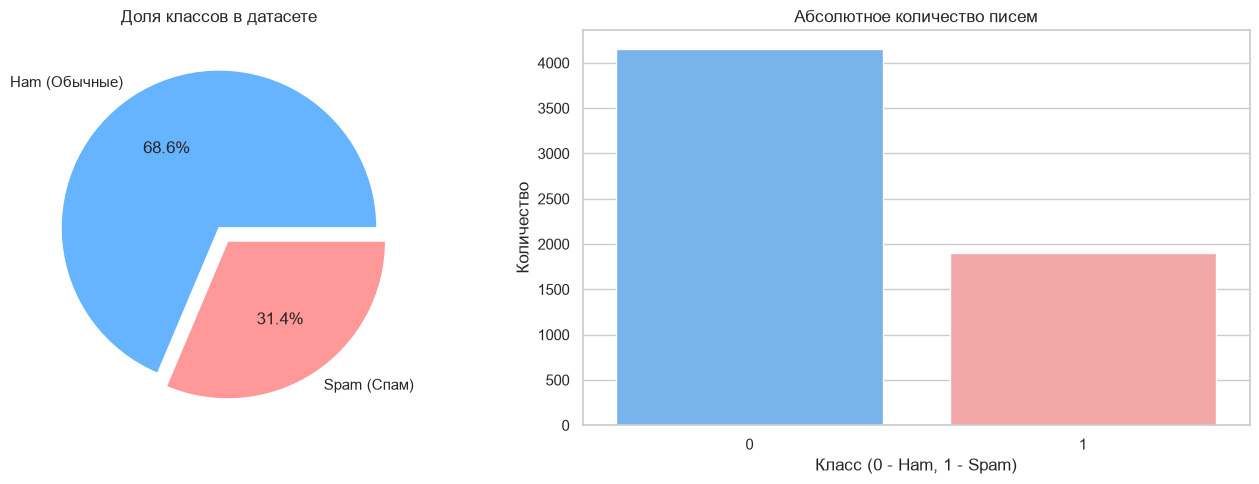

In [3]:
# Считаем распределение классов
class_counts = df['label'].value_counts()
print(f"Количество Ham (0): {class_counts[0]}")
print(f"Количество Spam (1): {class_counts[1]}")
print(f"Доля спама в датасете: {class_counts[1] / len(df):.2%}")

# Визуализация (Pie chart и Countplot )
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# График 1: Pie chart
df['label'].value_counts().plot(kind='pie', ax=axes[0], autopct='%1.1f%%', 
                                labels=['Ham (Обычные)', 'Spam (Спам)'], 
                                colors=['#66b3ff','#ff9999'], explode=(0, 0.1))
axes[0].set_ylabel('')
axes[0].set_title('Доля классов в датасете')

# График 2: Countplot
sns.countplot(data=df, x='label', ax=axes[1], palette=['#66b3ff','#ff9999'])
axes[1].set_title('Абсолютное количество писем')
axes[1].set_xlabel('Класс (0 - Ham, 1 - Spam)')
axes[1].set_ylabel('Количество')

plt.tight_layout()
plt.show()

В датасете присутствует умеренный дисбаланс классов: 69% обычных писем и 31% спама. 
Это подтверждает необходимость использовать F1-меру и матрицу ошибок. 
При обучении моделей необходимо использовать параметр class_weight='balanced', чтобы модель не игнорировала класс спама из-за его меньшей численности.

In [4]:
def extract_email_features(text):
    # 1. Длина темы и тела письма
    # Ищем "Subject:" в любом месте строки, берем текст до первого переноса (\n или \n)
    subject_match = re.search(r'Subject:\s*(.*?)(?:\\n|\n)', text, re.IGNORECASE)
    
    if subject_match:
        subject = subject_match.group(1)
        subject_length = len(subject)
        # Тело письма: всё, что идет после темы
        body = text[subject_match.end():].strip()
    else:
        subject_length = 0
        # Если темы нет, пытаемся отделить тело по двойному переносу
        parts = re.split(r'(?:\\n\\n|\n\n)', text, maxsplit=1)
        body = parts[1] if len(parts) > 1 else text
        
    body_length = len(body)
    
    #2. Количество спец. символов
    special_chars = string.punctuation
    num_special_chars = sum(1 for char in text if char in special_chars)
    
    #3. Наличие HTML-разметок
    is_html = 1 if re.search(r'<html|<body|<div|<a href|<p>', text, re.IGNORECASE) else 0
    
    #4. Количество URL-ссылок (http и https)
    num_links = len(re.findall(r'https?://', text, re.IGNORECASE))
    
    #5. Слова, написанные капсом (длиной более 3 символов)
    caps_words = len(re.findall(r'\b[A-Z]{3,}\b', text))
    
    return pd.Series([
        subject_length, body_length, num_special_chars, is_html, num_links, caps_words
    ])

# Список названий для новых колонок
feature_cols = [
    'subject_length', 'body_length', 'num_special_chars', 
    'is_html', 'num_links', 'caps_words'
]

# Применяем функцию к колонке с текстом
df[feature_cols] = df['text'].apply(extract_email_features)

# Строим сводную таблицу со средними значениями
summary = df.groupby('label')[feature_cols].mean().T
summary.columns = ['Ham (0)', 'Spam (1)']
summary['Difference'] = summary['Spam (1)'] - summary['Ham (0)']

# Выводим на экран, округляя до 2 знаков
display(summary.round(2))

,Ham (0),Spam (1),Difference
subject_length,39.25,41.67,2.42
body_length,1634.23,1992.49,358.27
num_special_chars,201.20,221.41,20.21
is_html,0.00,0.06,0.05
num_links,2.13,1.57,-0.56
caps_words,5.33,17.53,12.20


Длина темы и тела письма (subject_length и body_length): Спам-письма в среднем значительно длиннее обычных (из-за обилия рекламного текста).

Количество спе. символов (num_special_chars) показывают, что это спам. Обычный пользователь бы не стал ставить так часто спец. символы

HTML (is_html) и Капс (caps_words): Спам чаще использует HTML-верстку и слова, написанные капсом (например, "FREE", "URGENT").

Нам потребуется более глубокая проверка (pass/fail), но сам факт наличия технических заголовков в сыром тексте делает признак потенциально полезным.

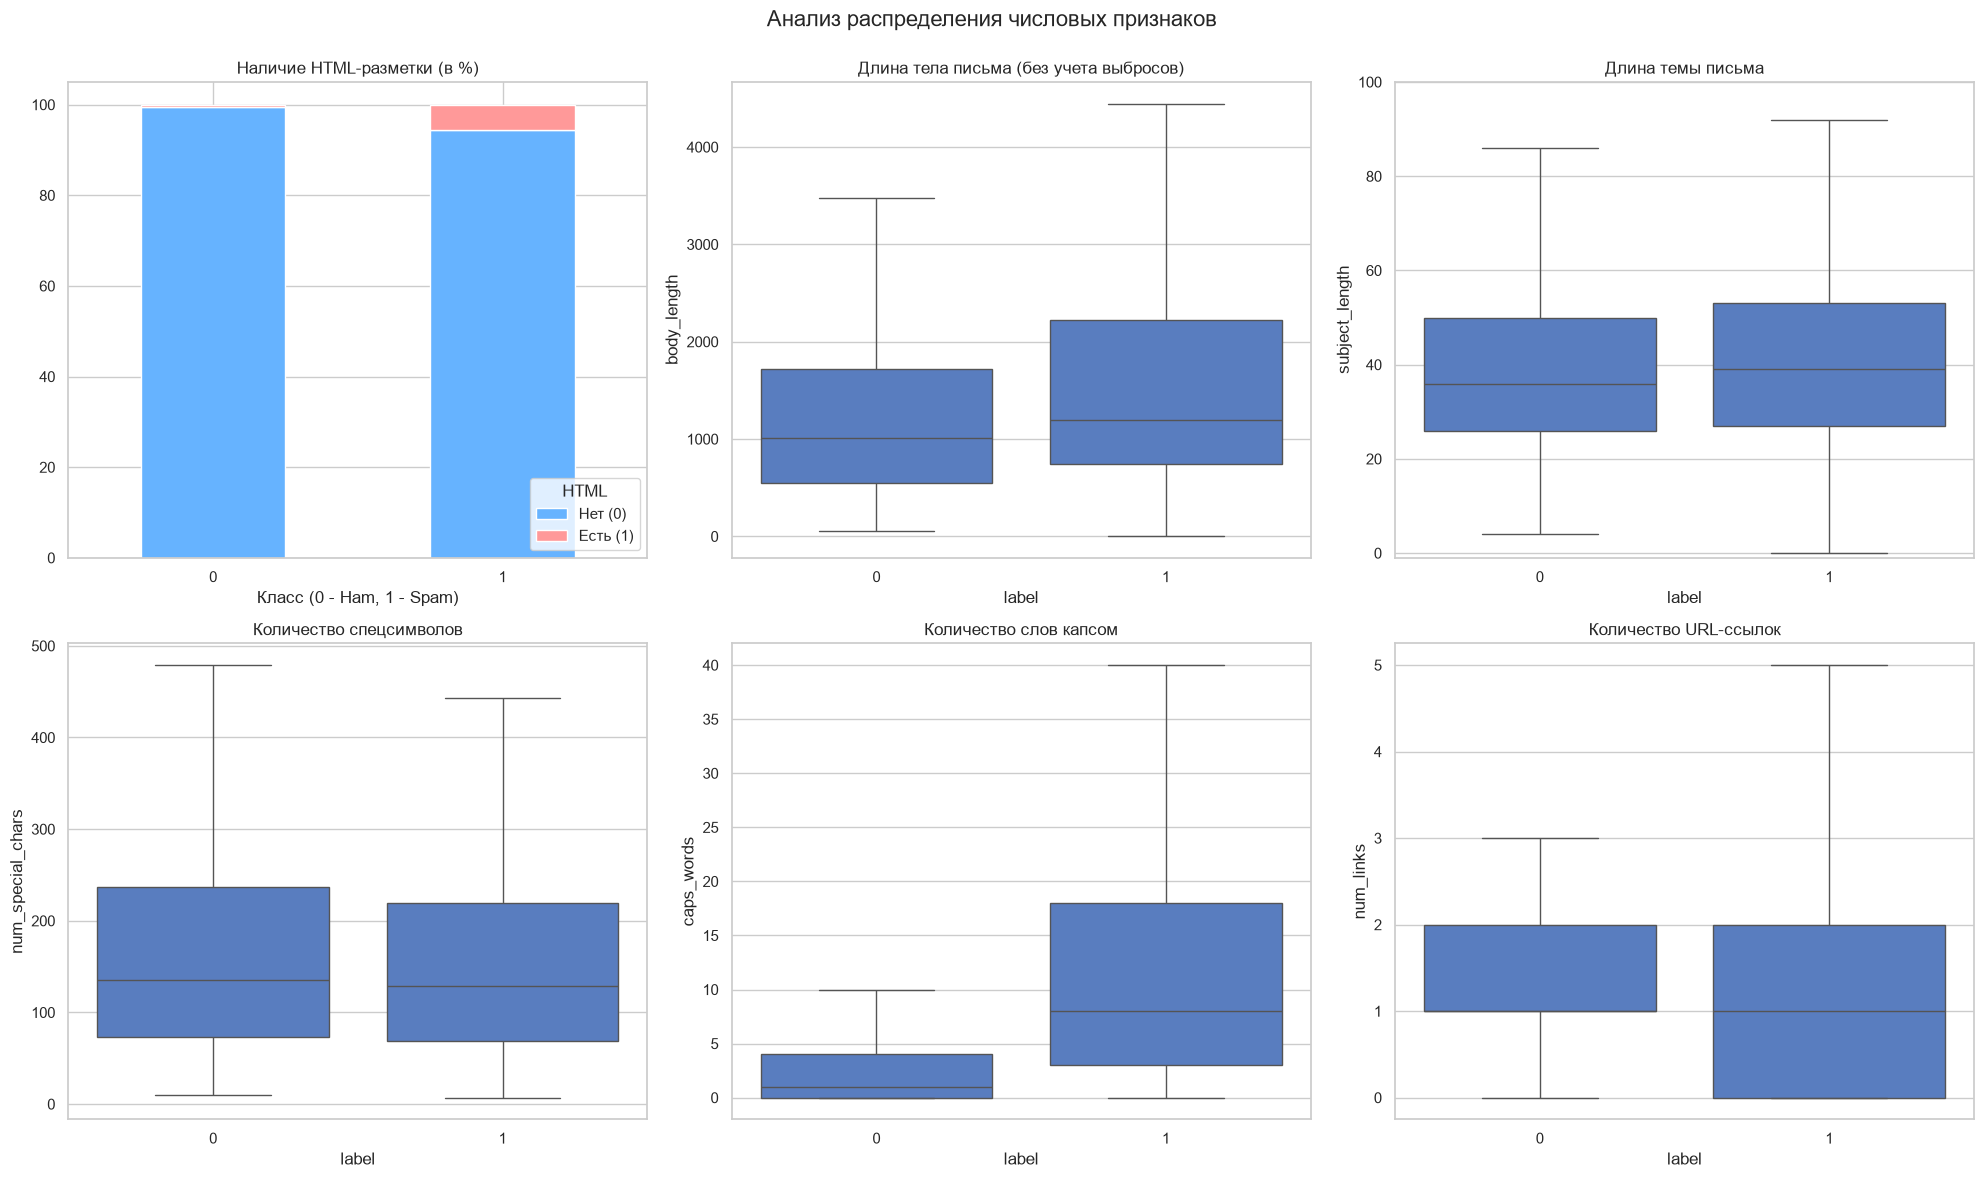

In [5]:
fig, axes = plt.subplots(2, 3, figsize=(20, 12))
fig.suptitle('Анализ распределения числовых признаков', fontsize=16)

# 1. Наличие HTML (Stacked Bar)
html_counts = df.groupby(['label', 'is_html']).size().unstack(fill_value=0)
html_percent = html_counts.div(html_counts.sum(axis=1), axis=0) * 100
html_percent.plot(kind='bar', stacked=True, ax=axes[0, 0], color=['#66b3ff','#ff9999'])
axes[0, 0].set_title('Наличие HTML-разметки (в %)')
axes[0, 0].set_xlabel('Класс (0 - Ham, 1 - Spam)')
axes[0, 0].legend(title='HTML', labels=['Нет (0)', 'Есть (1)'], loc='lower right')
axes[0, 0].tick_params(axis='x', rotation=0)

# 2. Длина тела письма (Boxplot без выбросов для читаемости)
sns.boxplot(data=df, x='label', y='body_length', ax=axes[0, 1], showfliers=False)
axes[0, 1].set_title('Длина тела письма (без учета выбросов)')

# 3. Длина темы письма (Boxplot)
sns.boxplot(data=df, x='label', y='subject_length', ax=axes[0, 2], showfliers=False)
axes[0, 2].set_title('Длина темы письма')
axes[0, 2].set_ylim(-1, 100) # Ограничим, так как темы короткие

# 4. Спецсимволы (Boxplot без выбросов)
sns.boxplot(data=df, x='label', y='num_special_chars', ax=axes[1, 0], showfliers=False)
axes[1, 0].set_title('Количество спецсимволов')

# 5. Слова капсом (Boxplot без выбросов)
sns.boxplot(data=df, x='label', y='caps_words', ax=axes[1, 1], showfliers=False)
axes[1, 1].set_title('Количество слов капсом')

# 6. Количество URL-ссылок (Boxplot без выбросов)
sns.boxplot(data=df, x='label', y='num_links', ax=axes[1, 2], showfliers=False)
axes[1, 2].set_title('Количество URL-ссылок')

plt.tight_layout()
fig.subplots_adjust(top=0.92) # Чтобы заголовок не наезжал на графики
plt.show()

Наиболее значимыми числовыми признаками для детекции спама являются наличие HTML-разметки и количество слов, написанных капсом. 
Признак длина тела письма - очень "коварный", так как длина может быть разной, включая самые огромные. Поэтому с ним необходимо будет поработать.
Признак спец. символы - стоит анализировать именно точечно, а именно количество каждого вида. Приведем анализ снизу

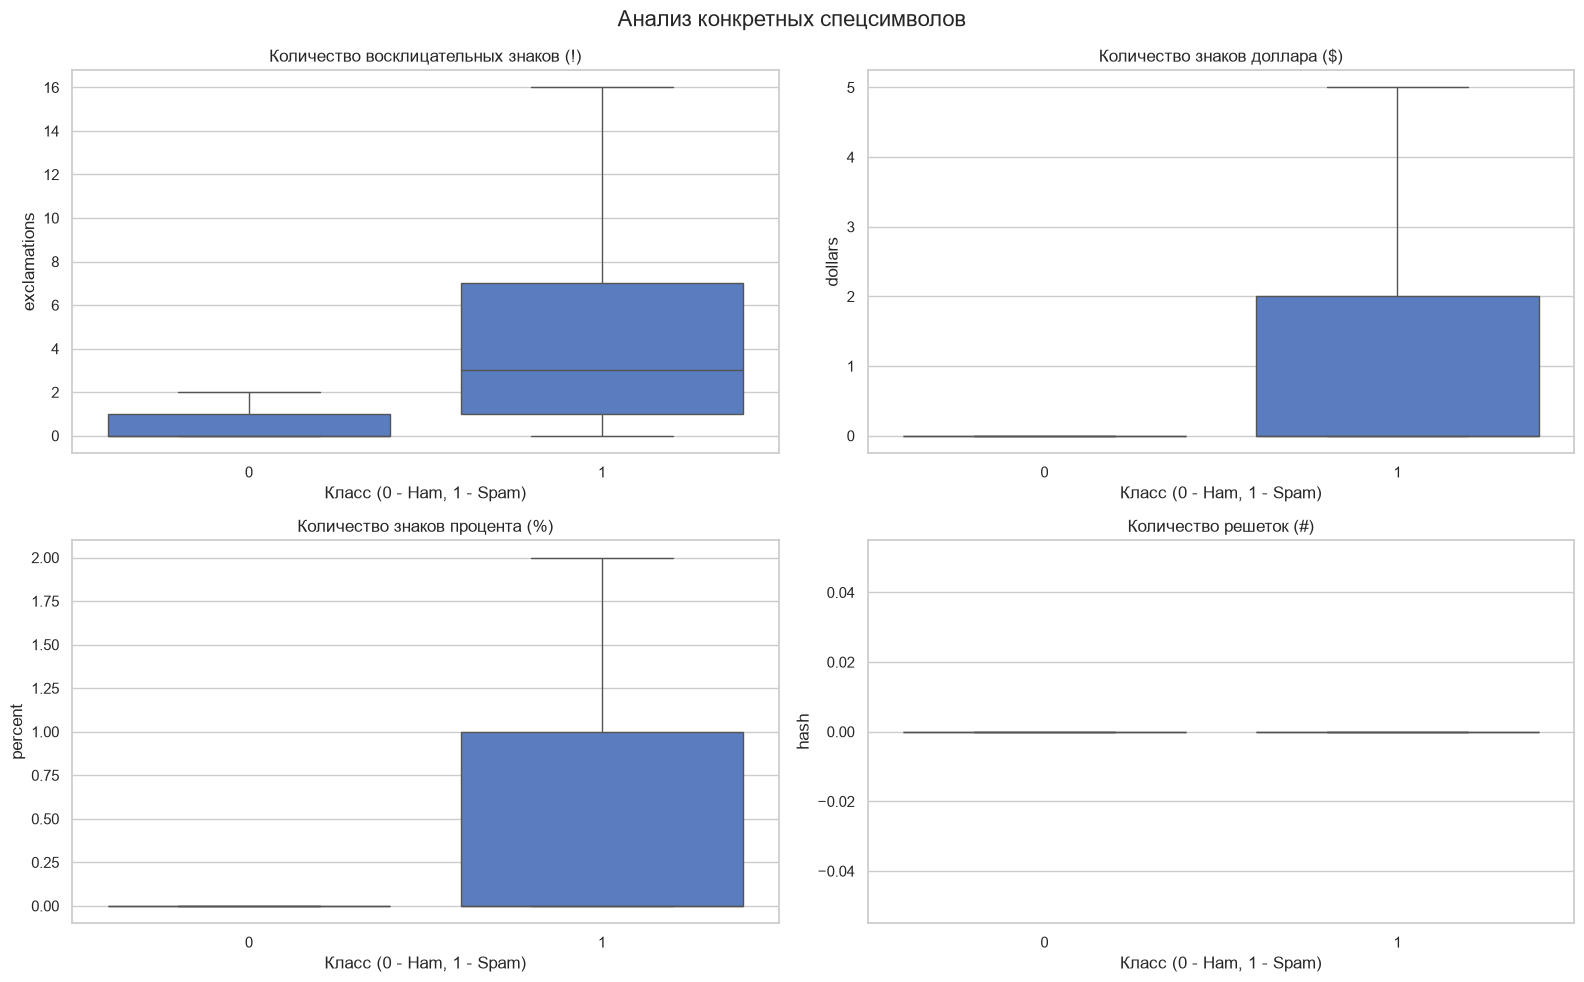

Среднее количество конкретных символов:
       exclamations  dollars  percent  hash
label                                      
0              0.76     0.47     0.34  1.49
1              5.39     2.84     3.72  1.90


In [6]:
# Создаем новые признаки для конкретных символов
df['exclamations'] = df['text'].apply(lambda x: x.count('!'))
df['dollars'] = df['text'].apply(lambda x: x.count('$'))
df['percent'] = df['text'].apply(lambda x: x.count('%'))
df['hash'] = df['text'].apply(lambda x: x.count('#'))

# Строим графики
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('Анализ конкретных спецсимволов', fontsize=16)

# 1. Восклицательные знаки
sns.boxplot(data=df, x='label', y='exclamations', ax=axes[0, 0], showfliers=False)
axes[0, 0].set_title('Количество восклицательных знаков (!)')
axes[0, 0].set_xlabel('Класс (0 - Ham, 1 - Spam)')

# 2. Знаки доллара
sns.boxplot(data=df, x='label', y='dollars', ax=axes[0, 1], showfliers=False)
axes[0, 1].set_title('Количество знаков доллара ($)')
axes[0, 1].set_xlabel('Класс (0 - Ham, 1 - Spam)')

# 3. Проценты
sns.boxplot(data=df, x='label', y='percent', ax=axes[1, 0], showfliers=False)
axes[1, 0].set_title('Количество знаков процента (%)')
axes[1, 0].set_xlabel('Класс (0 - Ham, 1 - Spam)')

# 4. Решетки
sns.boxplot(data=df, x='label', y='hash', ax=axes[1, 1], showfliers=False)
axes[1, 1].set_title('Количество решеток (#)')
axes[1, 1].set_xlabel('Класс (0 - Ham, 1 - Spam)')

plt.tight_layout()
fig.subplots_adjust(top=0.92)
plt.show()

# Выводим средние значения для новых признаков
print("Среднее количество конкретных символов:")
print(df.groupby('label')[['exclamations', 'dollars', 'percent', 'hash']].mean().round(2))

Наибольшую предсказательную силу показали признаки: 
is_html (наличие HTML-верстки), caps_words (слова капсом) и декомпозированные спецсимволы (exclamations, dollars, percent).
Таким образом, на спам влияют:
1) Длина письма в целом
2) Количество слов, написанных капсом 
3) Количество спец. симоволов и их тип 
4) Наличие HTML-кода

Из-за особенностей развитий технологий, анализ URL-ссылок в данном датасете не имеет смысла. 

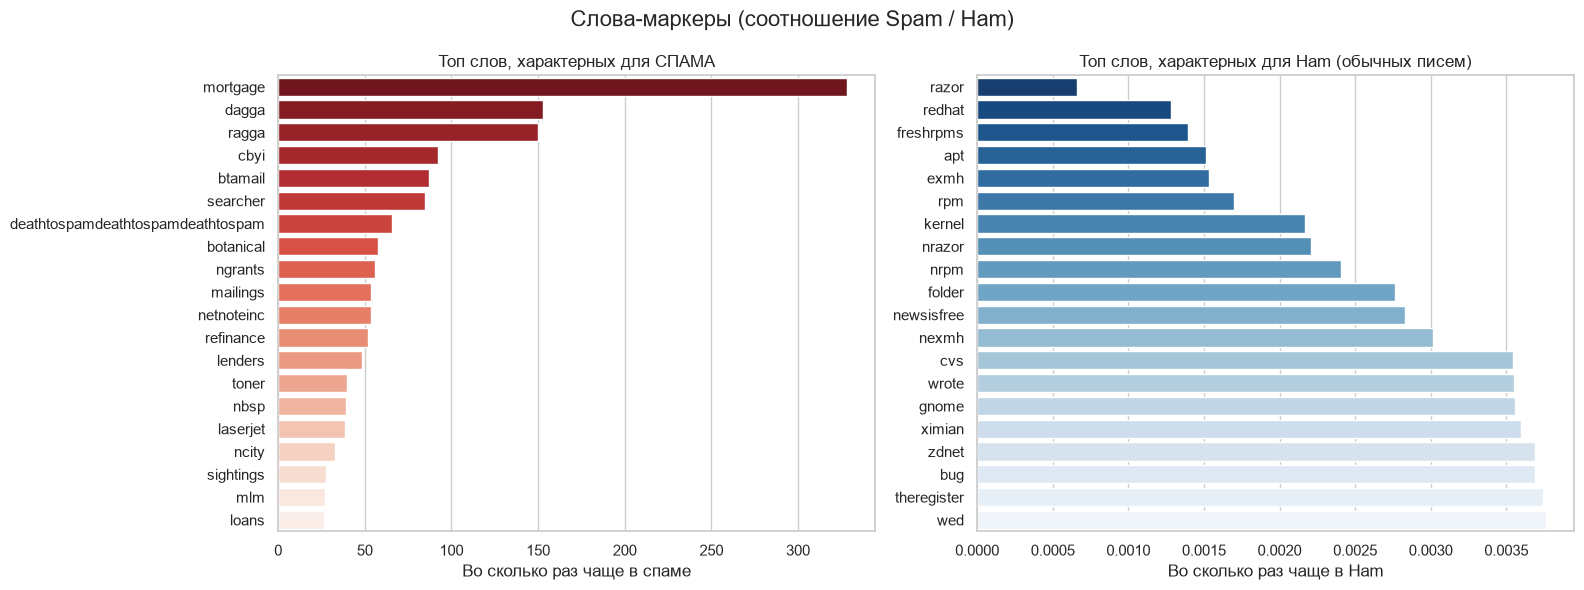

In [7]:
def get_specific_words(top_n=20):
    # 1. Очистка текста от HTML и мусора
    def clean(text):
        text = re.sub(r'<.*?>', ' ', text)
        text = re.sub(r'[^a-zA-Z\s]', ' ', text)
        return text.lower()
    
    df['clean_text'] = df['text'].apply(clean)
    
    # 2. Считаем частоту слов для каждого класса отдельно
    spam_texts = df[df['label'] == 1]['clean_text']
    ham_texts = df[df['label'] == 0]['clean_text']
    
    # Ограничиваем словарь (например, 2000 самых частых слов), чтобы не считать мусор
    vec = CountVectorizer(stop_words='english', max_features=2000)
    vec.fit(df['clean_text'])
    
    spam_matrix = vec.transform(spam_texts)
    ham_matrix = vec.transform(ham_texts)
    
    spam_counts = spam_matrix.sum(axis=0).A1
    ham_counts = ham_matrix.sum(axis=0).A1
    
    # Добавляем 1, чтобы избежать деления на ноль
    spam_counts += 1
    ham_counts += 1
    
    # 3. Считаем коэффициент (во сколько раз слово чаще в спаме)
    ratio = spam_counts / ham_counts
    words = vec.get_feature_names_out()
    
    # Создаем датафрейм
    df_words = pd.DataFrame({'Word': words, 'Ratio': ratio, 'Spam_Count': spam_counts, 'Ham_Count': ham_counts})
    
    # Убираем технические артефакты, которые мы заметили на графиках
    junk_words = ['xa', 'nhttp', 'com', 'http', 'www', 'subject', 'net', 'list', 'nth']
    df_words = df_words[~df_words['Word'].isin(junk_words)]
    
    # Берем топ слов для спама и для Ham
    top_spam = df_words.sort_values(by='Ratio', ascending=False).head(top_n)
    top_ham = df_words.sort_values(by='Ratio', ascending=True).head(top_n)
    
    return top_spam, top_ham

# Получаем результаты
top_spam_words, top_ham_words = get_specific_words()

# Визуализация
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Слова-маркеры (соотношение Spam / Ham)', fontsize=16)

# График для спама
sns.barplot(x='Ratio', y='Word', data=top_spam_words, ax=axes[0], palette='Reds_r')
axes[0].set_title('Топ слов, характерных для СПАМА')
axes[0].set_xlabel('Во сколько раз чаще в спаме')
axes[0].set_ylabel('')

# График для Ham
sns.barplot(x='Ratio', y='Word', data=top_ham_words, ax=axes[1], palette='Blues_r')
axes[1].set_title('Топ слов, характерных для Ham (обычных писем)')
axes[1].set_xlabel('Во сколько раз чаще в Ham')
axes[1].set_ylabel('')

plt.tight_layout()
plt.show()

Слова mortgage, lenders, refinance, mailings показывают, что встречаются в сотни раз чаще в спаме. Модель мгновенно выучит эти паттерны.

В Ham (обычных письмах) лидируют технические термины (razor, redhat, kernel, rpm). 

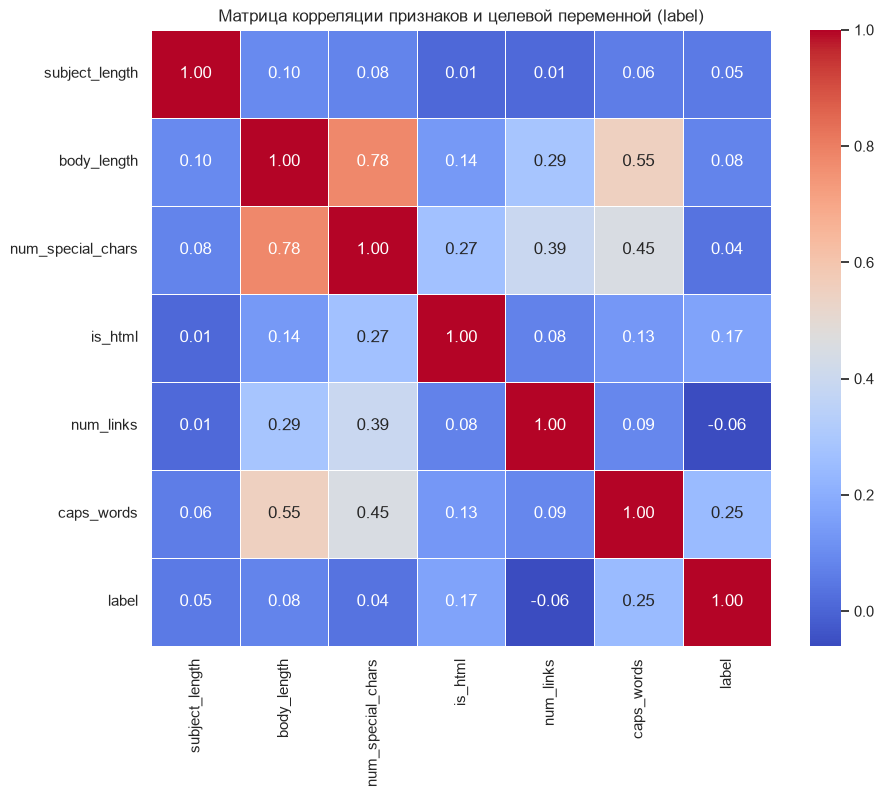

In [8]:
# Выбираем только наши числовые признаки и целевую переменную
corr_cols = feature_cols + ['label']
corr_matrix = df[corr_cols].corr()

# Строим Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Матрица корреляции признаков и целевой переменной (label)')
plt.show()

1. Связь признаков с целевой переменной (label):
caps_words (0.25): Наибольшая положительная корреляция. Чем больше слов капсом, тем выше вероятность, что это спам. 

is_html (0.17): Наличие HTML-верстки также является заметным маркером спама.

body_length (0.08) и subject_length (0.05): Очень слабая корреляция. 
Сама по себе длина письма почти не указывает на спам (так как письма могут быть длинными и там, и там).

num_links (-0.06): Отрицательная корреляция. Необходимо по-другому анализировать ссылки

2. Мультиколлинеарность (связь признаков друг с другом)

body_length и num_special_chars (0.78): Очень сильная связь! Это абсолютно логично: чем длиннее письмо, тем больше в нем знаков препинания. 
Для линейных моделей (например, Логистической регрессии) это может быть проблемой (мультиколлинеарность), и один из этих признаков, возможно, 
придется убрать или использовать регуляризацию.

body_length и caps_words (0.55): Умеренная связь. Длинные письма часто содержат больше слов капсом (например, длинные рекламные тексты).

num_links и num_special_chars (0.39): Умеренная связь, так как каждая ссылка содержит спецсимволы.